### Análise 1 — Evolução dos Atendimentos por Bairro (2022–2024)

Pergunta: Será que analisando o numero de atendimentos ao longo dos anos por diferentes opticas é possivel chegar em alguma conclusão significativa?

Esta análise tem como objetivo comparar a quantidade de atendimentos realizados pela Defesa Civil do Recife nos diferentes bairros da cidade, considerando os anos de 2022, 2023 e 2024.

A partir dos dados armazenados no banco PostgreSQL, serão identificados os bairros com maior número de atendimentos, além daqueles que apresentaram os maiores aumentos e reduções ao longo desse período. 

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from dotenv import load_dotenv

In [12]:
load_dotenv("../.env")

usuario = os.getenv("DB_USER")
senha = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST")
porta = os.getenv("DB_PORT")
banco = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql+psycopg2://{usuario}:{senha}@{host}:{porta}/{banco}"
)

with engine.connect() as conexao:
    print("Conexão realizada com sucesso!")

Conexão realizada com sucesso!


### Consultas

Primeiramente, vai ser montanda as tabelas necessarias para relacionar os bairros e a quantidade de atendimentos por ano.

Segundamente, serão calculadas as diferenças absolutas e percentuais no número de atendimentos por bairro entre 2022 e 2024, permitindo identificar quais localidades apresentaram crescimento ou redução no período.

In [13]:
# mesma consulta salva em analises/analise_1_evolucao_bairros.sql
consulta = open("../analises/analise_1_evolucao_bairros.sql", encoding="utf-8").read()

df_atendimentos = pd.read_sql(consulta, con=engine)

display(df_atendimentos.head(9))

,bairro,ano,total_atendimentos
0,Aflitos,2022,1
1,Aflitos,2023,17
2,Aflitos,2024,14
3,Afogados,2022,65
4,Afogados,2023,88
5,Afogados,2024,113
6,Agua Fria,2022,3601
7,Agua Fria,2023,2917
8,Agua Fria,2024,3114


In [14]:
df_evolucao = df_atendimentos.pivot_table(
    index="bairro",
    columns="ano",
    values="total_atendimentos",
    aggfunc="sum",# soma a partir dos parametros acima
    fill_value=0 # os nulls viram zero pra soma ocorrer
)

df_evolucao.columns = df_evolucao.columns.astype(str)
# preferido transformar em strings pra consultas futuras

display(df_evolucao.head(10))

ano,2022,2023,2024
bairro,,,
Aflitos,1,17,14
Afogados,65,88,113
Agua Fria,3601,2917,3114
Alto Da Bela Vista,40,0,0
Alto Do Eucalipto,32,1,0
Alto Do Mandu,6,1,19
Alto Do Maracana,0,0,4
Alto Jose Bonifacio,3226,2863,2291
Alto Jose Do Pinho,74,4,6


o output das celulas acima são um teste so pra saber se deu certo a montagem das tabelas

In [15]:
df_evolucao["variacao_absoluta"] = (
    df_evolucao["2024"] - df_evolucao["2022"]
)

df_evolucao["variacao 2022-2023"] = (
    df_evolucao["2023"] - df_evolucao["2022"]
)

df_evolucao["variacao 2023-2024"] = (
    df_evolucao["2024"] - df_evolucao["2023"]
)

df_evolucao["variacao_percentual_absoluta"] = (
    (df_evolucao["variacao_absoluta"] / df_evolucao["2022"].replace(0, float("nan"))) * 100
).round(2)

Obs: a variação absoluta foi representada como a variação entre o numero de atendimentos entre 2022 e 2024

A partir das variações calculadas, serão identificados os vinte bairros com os maiores aumentos e os vinte com as maiores reduções absolutas no número de atendimentos.

Essa comparação permitirá observar quais bairros tiveram as mudanças mais expressivas entre o início e o fim do período de anos analisado.

In [16]:
maiores_aumentos = df_evolucao.sort_values(
    by="variacao_absoluta",
    ascending=False
).head(20)

maiores_reducoes = df_evolucao.sort_values(
    by="variacao_absoluta",
    ascending=True
).head(20)

print("Bairros com maiores aumentos:")
display(maiores_aumentos)

print("Bairros com maiores reduções:")
display(maiores_reducoes)

Bairros com maiores aumentos:


ano,2022,2023,2024,variacao_absoluta,variacao 2022-2023,variacao 2023-2024,variacao_percentual_absoluta
bairro,,,,,,,
Varzea,3674,2508,5257,1583,-1166,2749,43.09
Dois Unidos,8412,8654,9702,1290,242,1048,15.34
Dois Irmaos,679,1204,1429,750,525,225,110.46
Morro Da Conceicao,529,426,1212,683,-103,786,129.11
Macaxeira,1725,2949,2316,591,1224,-633,34.26
Alto Santa Terezinha,285,621,698,413,336,77,144.91
Boa Vista,338,365,707,369,27,342,109.17
Imbiribeira,95,312,438,343,217,126,361.05
Sao Jose,152,1683,411,259,1531,-1272,170.39


Bairros com maiores reduções:


ano,2022,2023,2024,variacao_absoluta,variacao 2022-2023,variacao 2023-2024,variacao_percentual_absoluta
bairro,,,,,,,
Nova Descoberta,11518,9766,7557,-3961,-1752,-2209,-34.39
Cohab,14220,11554,12060,-2160,-2666,506,-15.19
Guabiraba,3795,1974,2205,-1590,-1821,231,-41.90
Corrego Do Jenipapo,1267,1544,1,-1266,277,-1543,-99.92
Passarinho,2949,2135,1959,-990,-814,-176,-33.57
Alto Jose Bonifacio,3226,2863,2291,-935,-363,-572,-28.98
Barro,2337,1264,1485,-852,-1073,221,-36.46
Linha Do Tiro,3558,2495,2847,-711,-1063,352,-19.98
Jordao,3221,2723,2580,-641,-498,-143,-19.90


Obs: Nessa tabela já da pra perceber discrepâncias entre a quantidade de atendimentos anuais, o bairro do Corrego do Jenipapo é o caso mais drastico desse tipo, por que será que no ano de 2024 so teve 1 atendimento registrado nos dados da defesa civil?

Evolução geral dos atendimentos

O gráfico a seguir apresenta a quantidade total de atendimentos por ano, considerando os bairros identificados na base de dados.

Essa visualização permite observar se houve crescimento ou redução no volume geral de atendimentos entre 2022 e 2024.

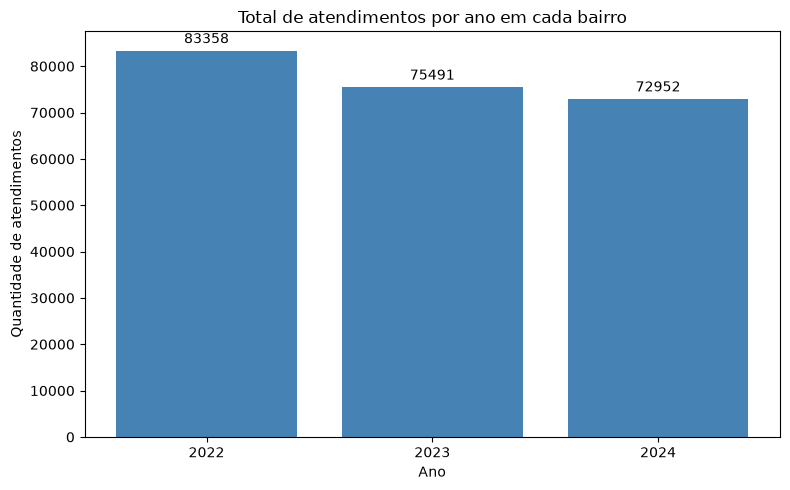

In [17]:
total_por_ano = df_evolucao[["2022", "2023", "2024"]].sum()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    total_por_ano.index,
    total_por_ano.values,
    color="steelblue"
)

plt.bar_label(barras, padding=3)

plt.title("Total de atendimentos por ano em cada bairro")
plt.xlabel("Ano")
plt.ylabel("Quantidade de atendimentos")

plt.tight_layout()
plt.show()

Pelo gráfico acima, é possível notar que o ano de 2022, entre os analisados, foi o que apresentou o maior número de atendimentos documentados, fenômeno esse que possivelmente está relacionado às chuvas extremas que atingiram a Região Metropolitana do Recife em meados de 2022 e aos seus desdobramentos.

Comparação dos bairros usando a variação absoluta como referencial

Os gráficos gerados abaixo destacam os bairros que apresentaram as maiores mudanças absolutas no número de atendimentos entre 2022 e 2024, separando os aumentos das reduções.

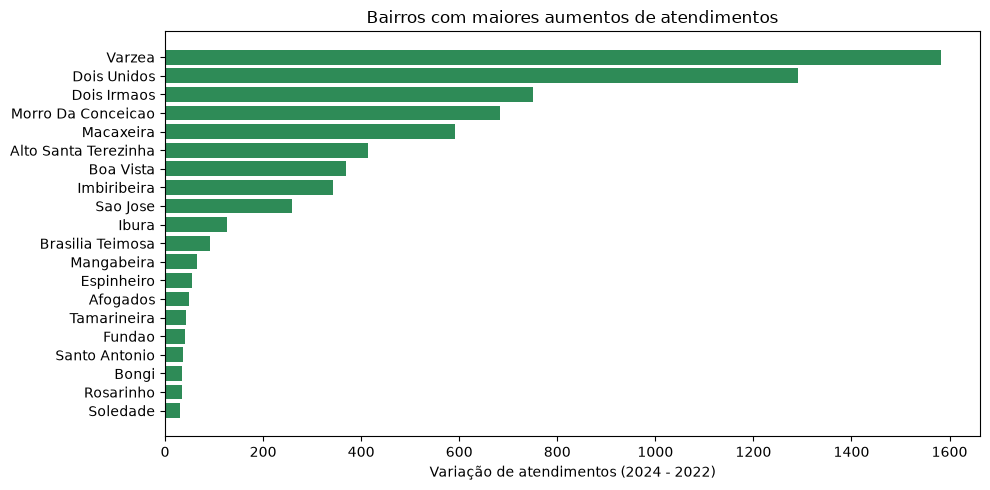

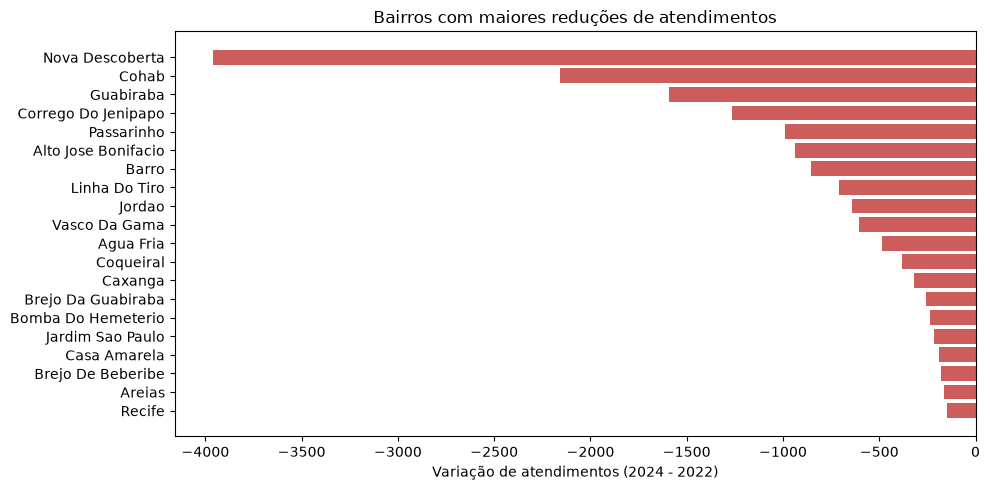

In [18]:
aumentos = maiores_aumentos[
    maiores_aumentos["variacao_absoluta"] > 0
].sort_values("variacao_absoluta")

reducoes = maiores_reducoes[
    maiores_reducoes["variacao_absoluta"] < 0
].sort_values("variacao_absoluta", ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(
    aumentos.index,
    aumentos["variacao_absoluta"],
    color="seagreen"
)

plt.title("Bairros com maiores aumentos de atendimentos")
plt.xlabel("Variação de atendimentos (2024 - 2022)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.barh(
    reducoes.index,
    reducoes["variacao_absoluta"],
    color="indianred"
)

plt.title("Bairros com maiores reduções de atendimentos")
plt.xlabel("Variação de atendimentos (2024 - 2022)")
plt.tight_layout()
plt.show()

### Análise complementar — Categorias de ação na Várzea

Como a Várzea apresentou o maior crescimento absoluto de atendimentos
entre 2022 e 2024, é interesante se aprofundar e investigar esse aumento, por isso, serão comparadas as quantidades de atendimentos por categoria de ação nos três anos.

In [19]:

# lê a consulta complementar
consulta_varzea = open(
    "../analises/analise_1_acoes_varzea.sql",
    encoding="utf-8"
).read()

# executa a consulta
df_varzea = pd.read_sql(consulta_varzea, con=engine)

# mostra os resultados
display(df_varzea)


,categoria_acao,ano,total_atendimentos
0,Assistência humanitária,2022,152
1,Assistência humanitária,2023,26
2,Assistência humanitária,2024,26
3,Assistência social,2022,815
4,Assistência social,2023,697
5,Assistência social,2024,1979
6,Avaliação técnica de risco,2022,1302
7,Avaliação técnica de risco,2023,83
8,Avaliação técnica de risco,2024,127
9,Encaminhamentos,2022,33


Com o output de cima já da pra perceber que o aumento e a redução não foram regulares para todas as categoria da ação, para obter uma melhor analise, é importante criar uma tabela com cada tipo de atendimento e sua variação absoluta

In [20]:

# organiza as categorias nas linhas e os anos nas colunas
df_comparacao_varzea = df_varzea.pivot_table(
    index="categoria_acao",
    columns="ano",
    values="total_atendimentos",
    aggfunc="sum",
    fill_value=0
)

# calcula a diferença entre 2024 e 2022
df_comparacao_varzea["variacao_absoluta"] = (
    df_comparacao_varzea["2024"] - df_comparacao_varzea["2022"]
)

# organiza da categoria que mais aumentou para a que mais diminuiu
df_comparacao_varzea = df_comparacao_varzea.sort_values(
    by="variacao_absoluta",
    ascending=False
)

display(df_comparacao_varzea)

ano,2022,2023,2024,variacao_absoluta
categoria_acao,,,,
não informado,514,1319,1984,1470
Assistência social,815,697,1979,1164
Prevenção e orientação,683,238,978,295
Encaminhamentos,33,32,35,2
Manutenção e obras,145,112,126,-19
Remoção de famílias,30,1,2,-28
Assistência humanitária,152,26,26,-126
Avaliação técnica de risco,1302,83,127,-1175


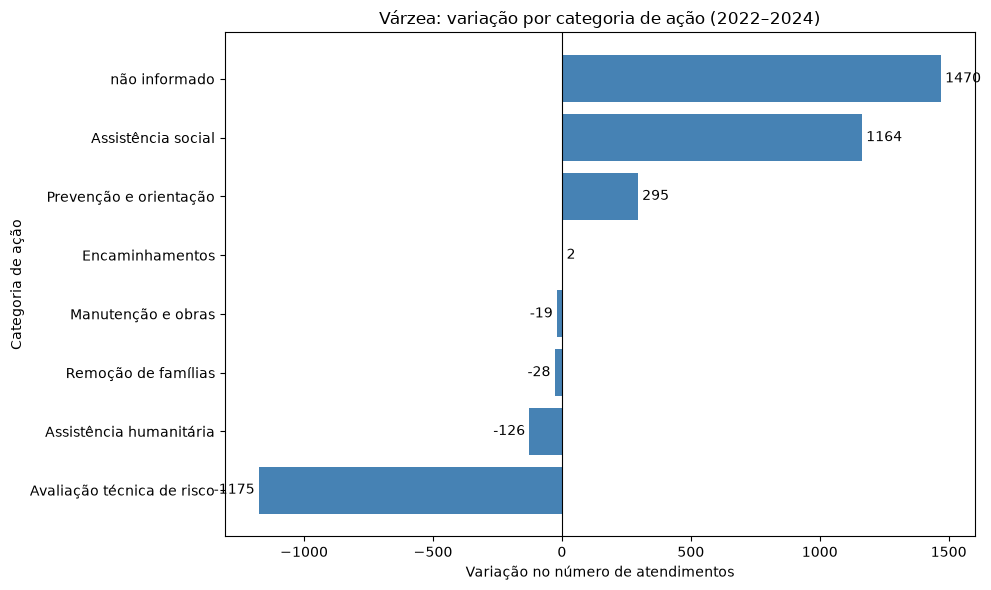

In [21]:

# organiza as categorias para o gráfico
dados_grafico = df_comparacao_varzea.sort_values(
    by="variacao_absoluta"
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    dados_grafico.index,
    dados_grafico["variacao_absoluta"],
    color="steelblue"
)

plt.bar_label(barras, padding=3)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Variação no número de atendimentos")
plt.ylabel("Categoria de ação")
plt.title("Várzea: variação por categoria de ação (2022–2024)")

plt.tight_layout()
plt.show()


A primeira tabela gerada mostra com mais detalhes a quantidade de atendimentos por categoria em cada ano. Já com o gráfico, é possível visualizar mais claramente quais categorias apresentaram os maiores aumentos e reduções entre 2022 e 2024, destacando principalmente o crescimento da assistência social e dos registros classificados como "não informado", além da queda nas avaliações técnicas de risco.

### Análise complementar — Investigação de Córrego do Jenipapo

A análise inicial identificou uma queda expressiva nos atendimentos
de Córrego do Jenipapo em 2024, para investigar essa diferença,
serão analisados os registros que apresentam o nome Jenipapo
nas colunas bairro ou localidade.

In [23]:

# lê o arquivo SQL
consulta_jenipapo = open(
    "../analises/analise_1_corrego_jenipapo.sql",
    encoding="utf-8"
).read()

# executa a consulta no banco
df_jenipapo = pd.read_sql(consulta_jenipapo, con=engine)

# mostra os resultados
display(df_jenipapo)

,bairro,localidade,ano,total_atendimentos
0,Brejo Da Guabiraba,Corrego Do Jenipapo,2024,16
1,Corrego Do Fernandinho,Corrego Do Jenipapo,2022,1
2,Corrego Do Jenipapo,Alto Da Loura,2022,12
3,Corrego Do Jenipapo,Alto Jose Idalino,2022,2
4,Corrego Do Jenipapo,Corrego Da Loura,2022,15
5,Corrego Do Jenipapo,Corrego Da Loura,2023,18
6,Corrego Do Jenipapo,Corrego Do Aprigio,2023,27
7,Corrego Do Jenipapo,Corrego Do Fernandinho,2022,113
8,Corrego Do Jenipapo,Corrego Do Fernandinho,2023,129
9,Corrego Do Jenipapo,Corrego Do Jenipapo,2022,894


A consulta acima permitiu identificar os registro que apresentam a palavra jenipapo em alguma das suas colunas

In [24]:

# compara os registros de Jenipapo por ano
df_resumo_jenipapo = df_jenipapo.groupby("ano").apply(
    lambda grupo: pd.Series({
        "como_bairro": grupo.loc[
            grupo["bairro"] == "Corrego Do Jenipapo",
            "total_atendimentos"
        ].sum(),

        "como_localidade": grupo.loc[
            grupo["localidade"] == "Corrego Do Jenipapo",
            "total_atendimentos"
        ].sum(),

        "total_relacionado": grupo["total_atendimentos"].sum()
    }),
    include_groups=False
)

display(df_resumo_jenipapo)

,como_bairro,como_localidade,total_relacionado
ano,,,
2022,1267,1517,1890
2023,1544,966,1564
2024,1,1004,1005


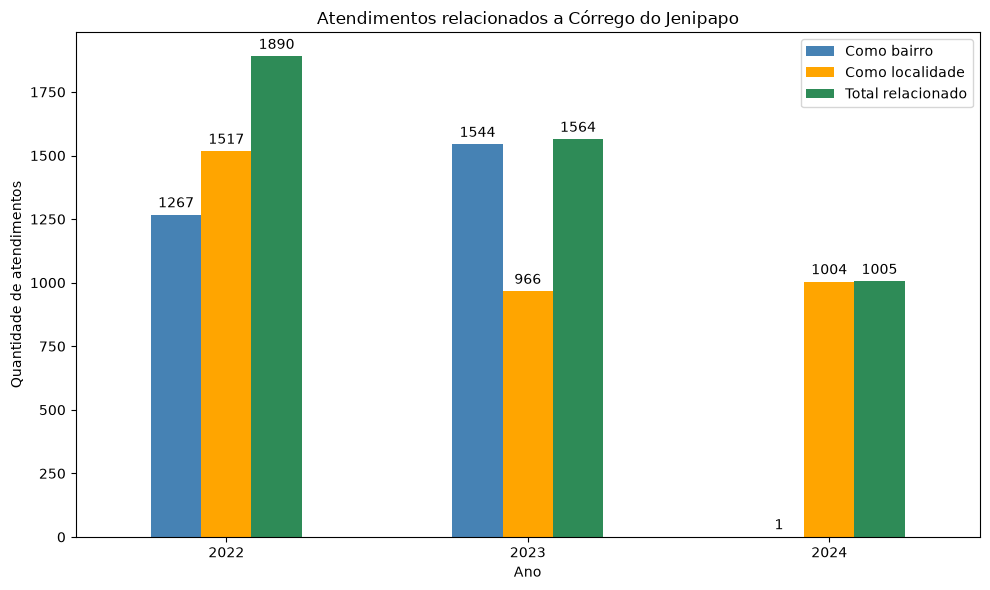

In [25]:

# seleciona os dados para o gráfico
dados_jenipapo = df_resumo_jenipapo[
    ["como_bairro", "como_localidade", "total_relacionado"]
]

# cria o gráfico de barras
ax = dados_jenipapo.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange", "seagreen"]
)

# adiciona os valores nas barras
for barras in ax.containers:
    ax.bar_label(barras, padding=3)

plt.title("Atendimentos relacionados a Córrego do Jenipapo")
plt.xlabel("Ano")
plt.ylabel("Quantidade de atendimentos")

plt.xticks(rotation=0)

plt.legend([
    "Como bairro",
    "Como localidade",
    "Total relacionado"
])

plt.tight_layout()
plt.show()


A tabela e o gráfico acima permite a comparação entre os registros de bairro e localidade, assim, revelando uma diferença significativa na classificação dos atendimentos relacionados a Córrego do Jenipapo. Embora os registros associados diretamente ao bairro tenham praticamente desaparecido em 2024, a localidade continuou apresentando uma quantidade expressiva de atendimentos. Isso sugere que parte da queda identificada na análise inicial pode estar relacionada à forma como os registros foram classificados.

### Insights

A pergunta inicial foi: Será que analisando o número de atendimentos ao longo dos anos por diferentes perspectivas, é possível chegar a alguma conclusão significativa?

A resposta para essa pergunta seria sim, já que foram encontrados dados interessantes, alguns dos quais podem estar relacionados a acontecimentos locais. Entre eles, é importante ressaltar a análise de três bairros específicos: Várzea, Nova Descoberta e Córrego do Jenipapo.

O bairro da Várzea lidera o gráfico de aumento de atendimentos, passando de 3.674 registros em 2022 para 5.257 em 2024, um crescimento de aproximadamente 43,09%. Esse aumento foi especialmente expressivo entre 2023 e 2024, quando o número de atendimentos mais que dobrou.

Esse comportamento pode estar relacionado aos problemas de drenagem e alagamentos presentes em determinadas áreas do bairro, fato identificado pelo estudo apresentado no XV Encontro Nacional de Águas Urbanas. Além disso, em junho de 2024, a estação pluviométrica da Várzea registrou 154,3 mm de chuva em 24 horas, o que pode ter contribuído para o aumento das ocorrências, conforme notícia do Diário de Pernambuco.

Para aprofundar essa investigação, foi realizada uma análise complementar das categorias de ação registradas na Várzea. Os resultados mostraram que a categoria Assistência social apresentou um aumento de 1.164 atendimentos entre 2022 e 2024, enquanto Avaliação técnica de risco teve uma redução de 1.175 registros. Entretanto, o maior crescimento ocorreu na categoria "não informado", com 1.470 registros a mais. Isso mostra que, apesar de ser possível identificar mudanças no perfil dos atendimentos, a quantidade de registros sem classificação limita uma conclusão mais precisa sobre as causas desse crescimento.

Já o bairro de Nova Descoberta apresenta uma redução constante no número de atendimentos ao longo dos anos. No final de 2022, o bairro recebeu investimentos em obras de contenção de encostas e drenagem. Apesar de poder existir uma relação entre essas obras e a redução de determinadas situações de risco, não é possível afirmar com certeza que essa tenha sido a causa da diminuição dos registros.

Outro caso que chamou atenção foi Córrego do Jenipapo, que passou de 1.544 atendimentos em 2023 para apenas 1 em 2024. Inicialmente, essa diferença levantou dúvidas sobre uma possível ausência de registros ou uma redução real das ocorrências.

Entretanto, a análise complementar das colunas bairro e localidade revelou uma possível explicação para essa discrepância. Em 2024, foram encontrados 985 atendimentos classificados no bairro Guabiraba, mas com Córrego do Jenipapo como localidade. Além disso, ao considerar todos os registros relacionados ao nome Jenipapo, seja como bairro ou localidade, o total passou de 1.564 em 2023 para 1.005 em 2024, uma redução de aproximadamente 35,74%, bem menor que a observada inicialmente.

Isso sugere que parte da queda muito provavelmente está relacionada a diferenças na classificação territorial dos registros, ou seja a partir do ano de 2024 a classificação dos atendimentos pararam de registrar o Corrégo do Jenipapo como bairro e sim somente como localidade, e não necessariamente ao desaparecimento das ocorrências naquela região

Portanto, a análise mostrou que observar apenas a quantidade de atendimentos por bairro pode não ser suficiente para compreender a totalidade de determinadas variações, jAs análises complementares permitiram identificar mudanças nas categorias de ação e possíveis inconsistências na classificação territorial, demonstrando a importância de investigar os dados por diferentes perspectivas antes de chegar a conclusões.

### Fontes

https://files.abrhidro.org.br/Eventos/Trabalhos/238/XV-ENAU0125-1-0-20240801-102239.pdf

https://www.diariodepernambuco.com.br/noticia/vidaurbana/2024/06/recife-teve-o-maior-volume-de-chuva-em-24h-desde-maio-de-2022.html

https://www.diariodepernambuco.com.br/noticia/vidaurbana/2022/11/prefeitura-do-recife-avanca-com-obras-de-contencao-de-encosta-em-nova.html